In [20]:
%pip install -q -e ../preprocessing

import os
import sys
import importlib
import matplotlib.pyplot as plt

# Ensure the preprocessing package is discoverable from the notebook
project_root = os.path.abspath("..")
preprocessing_dir = os.path.join(project_root, "preprocessing")

if preprocessing_dir not in sys.path:
    sys.path.insert(0, preprocessing_dir)

import image_preprocessing
importlib.reload(image_preprocessing)

<module 'image_preprocessing' from 'd:\\AI-Powered-Diabetic-Retinopathy-System\\ml-model\\preprocessing\\image_preprocessing.py'>

In [32]:
from image_preprocessing import (
    load_image,
    resize_image,
    display_image,
    enhance_contrast,
    
)

print("Functions Imported Successfully!")

Functions Imported Successfully!


In [33]:
image_path = "D:\\AI-Powered-Diabetic-Retinopathy-System\\ml-model\\dataset\\raw\\train_images\\00e4ddff966a.png"

In [34]:
from image_preprocessing import load_image

image = load_image(image_path)

print("Image Loaded Successfully!")
print(image.shape)

Image Loaded Successfully!
(1736, 2416, 3)


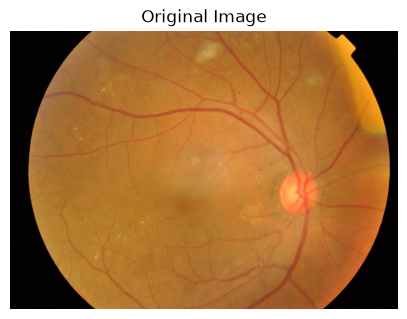

In [35]:
from image_preprocessing import display_image

display_image(image, "Original Image")

In [36]:
from image_preprocessing import resize_image
resized_image = resize_image(image)

In [37]:
print("Original Shape :", image.shape)

print("Resized Shape :", resized_image.shape)

Original Shape : (1736, 2416, 3)
Resized Shape : (224, 224, 3)


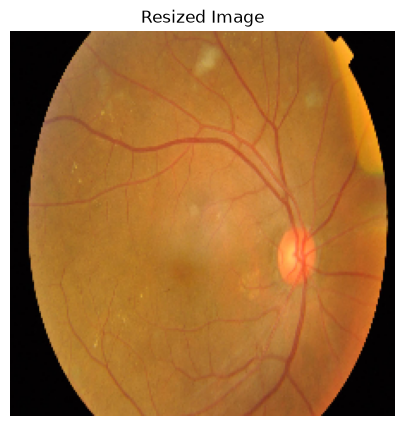

In [38]:
display_image(resized_image, "Resized Image")

In [39]:
from image_preprocessing import crop_black_border

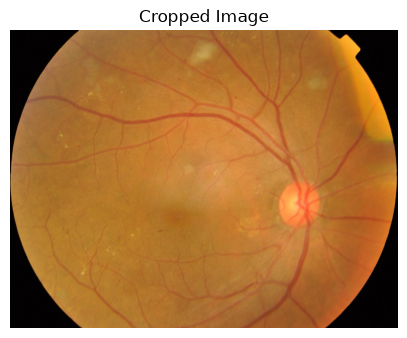

In [40]:
cropped = crop_black_border(image)

display_image(cropped, "Cropped Image")

In [15]:
print("Original Shape :", image.shape)

print("Cropped Shape :", cropped.shape)

Original Shape : (1736, 2416, 3)
Cropped Shape : (1736, 2260, 3)


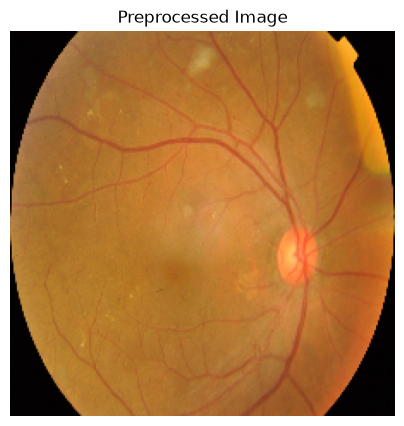

In [41]:
cropped = crop_black_border(image)

resized = resize_image(cropped)

display_image(resized, "Preprocessed Image")

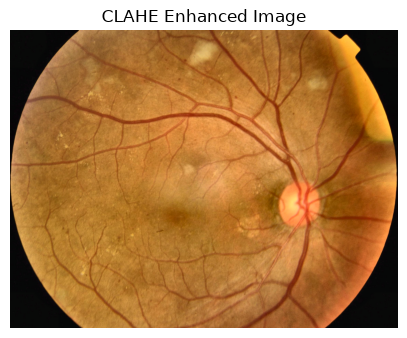

In [42]:
from image_preprocessing import enhance_contrast
enhanced = enhance_contrast(cropped)

display_image(
    enhanced,
    "CLAHE Enhanced Image"
)

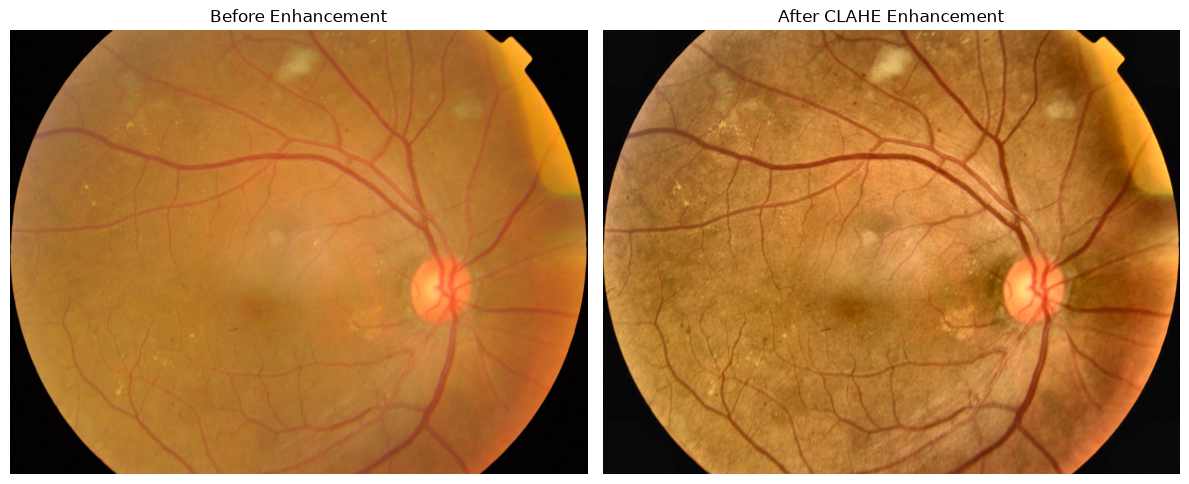

In [43]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cropped)
plt.title("Before Enhancement")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(enhanced)
plt.title("After CLAHE Enhancement")
plt.axis("off")

plt.tight_layout()
plt.show()

In [45]:
# ml-model/preprocessing/image_preprocessing.py
import numpy as np

def normalize_image(image, dtype=np.float32):
    img = np.asarray(image)
    if img.dtype != np.float32:
        img = img.astype(np.float32)

    # If pixel values are in [0, 255], scale to [0, 1]
    if img.max() > 1.0:
        img = img / 255.0

    return img.astype(dtype)
normalized = normalize_image(enhanced)

print("Minimum pixel value:", normalized.min())
print("Maximum pixel value:", normalized.max())
print("Data type:", normalized.dtype)

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data type: float32
